
 TRANSIENT BATCH EVALUATION: 300 CIRCUITS (DOUBLE TAIL STRONG-ARM LATCH)
Compiled Custom DC, AC, and Transient Simulator Successfully!

>>> Running 300-Batch Transient Solves on 20 Julia Threads...
Julia 300-Circuit Transient Total Time: 8.545 s
    Saved fresh Julia results to: C:\Users\mohamed\Desktop\ML\CAD_projects\Netlists\GF_180nm_tech_work\project\New_Sim_tests\Allah_help_me2\Allah_Save_me\New folder\system\Testing\Spice_vs_Julia_Benchmarking\julia_strongarm_cache_300.jld2

>>> Running LTspice baseline (Sequential)...
    LTspice progress: 30/300 circuits done...
    LTspice progress: 60/300 circuits done...
    LTspice progress: 90/300 circuits done...
    LTspice progress: 120/300 circuits done...
    LTspice progress: 150/300 circuits done...
    LTspice progress: 180/300 circuits done...
    LTspice progress: 210/300 circuits done...
    LTspice progress: 240/300 circuits done...
    LTspice progress: 270/300 circuits done...
    LTspice progress: 300/300 circuits done...
L

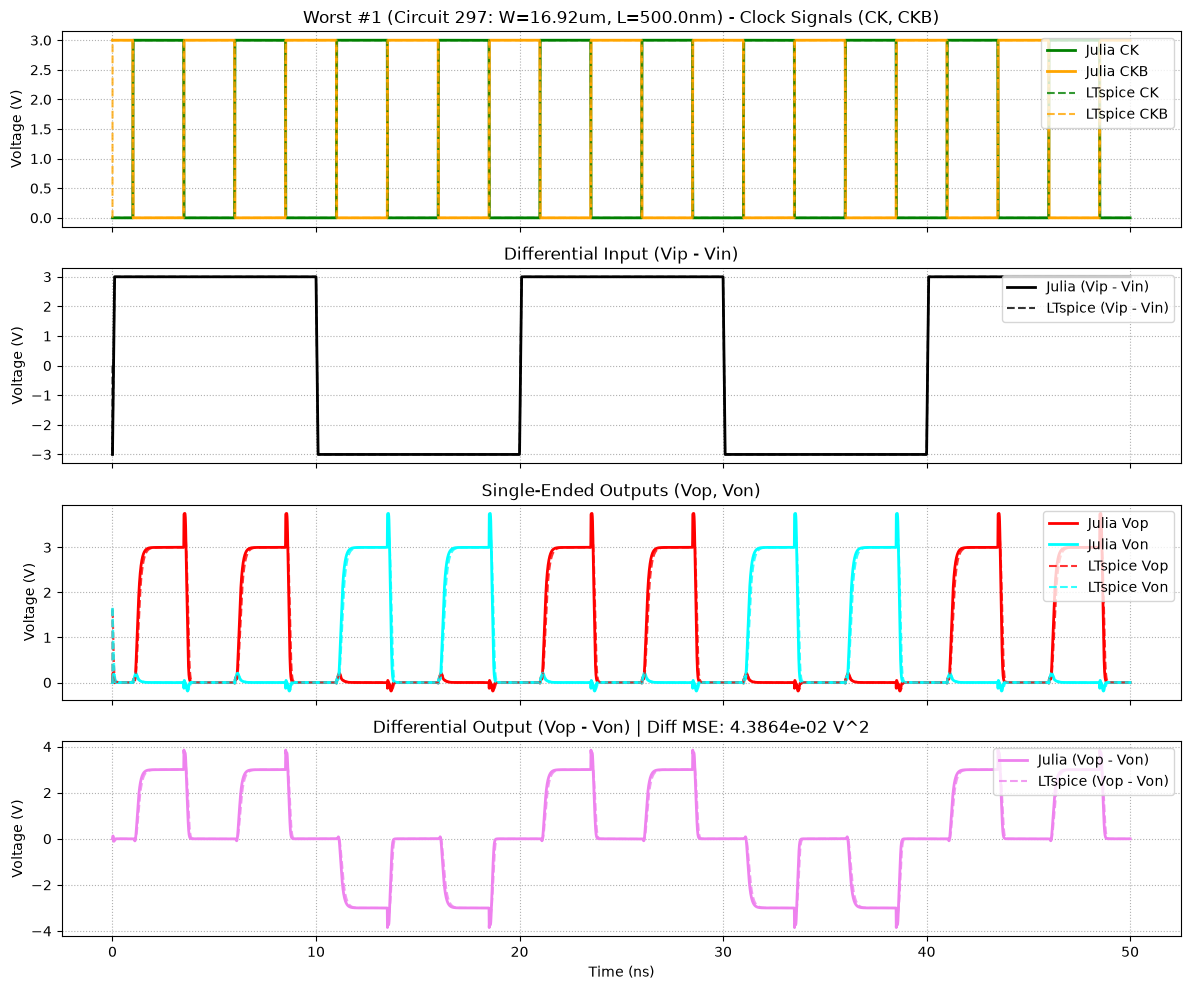


 Worst Case #2 | Circuit 287 | W = 6.66 um | L = 500.0 nm | Diff MSE = 4.3851e-02 V^2


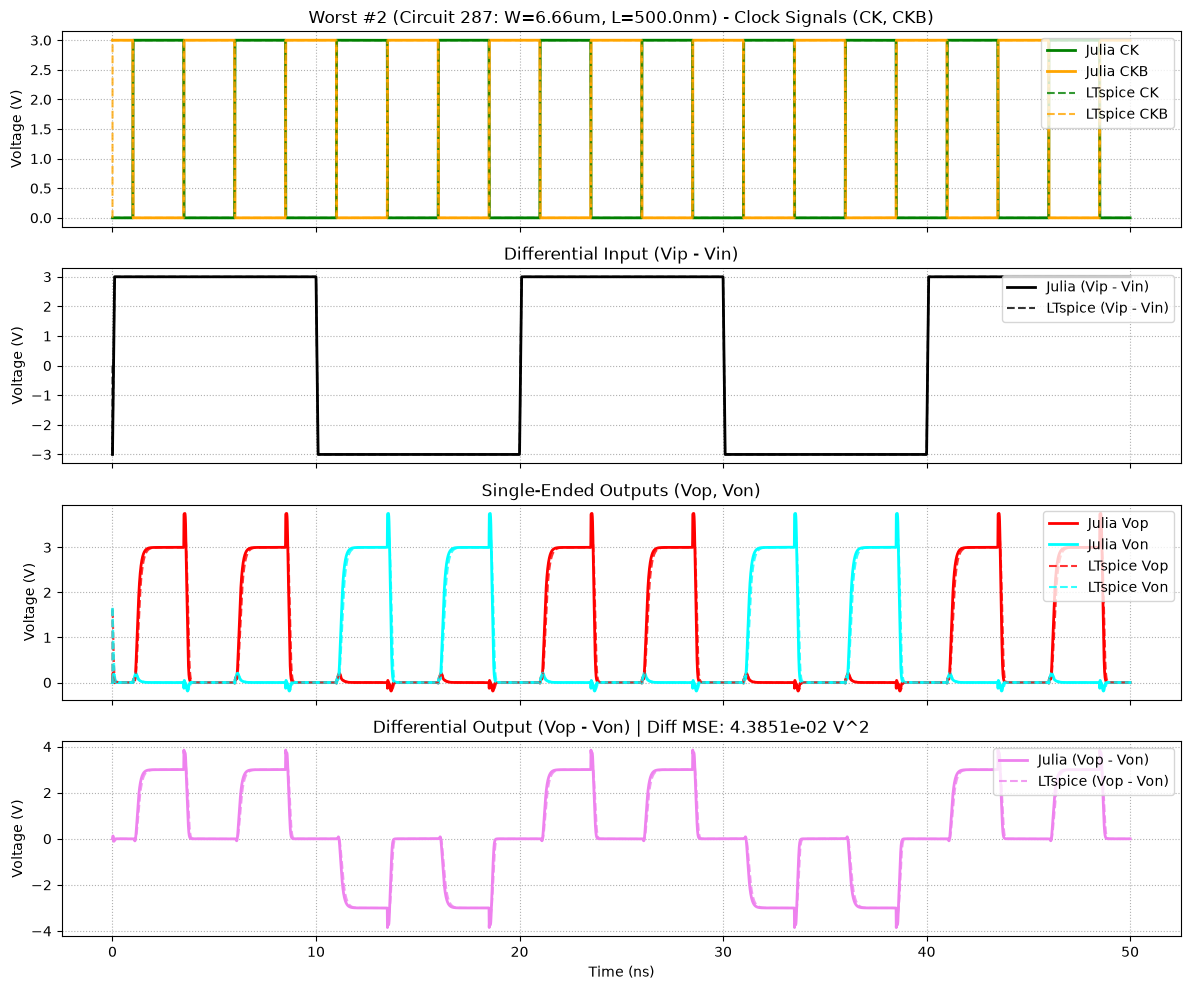


 Worst Case #3 | Circuit 286 | W = 5.63 um | L = 500.0 nm | Diff MSE = 4.3847e-02 V^2


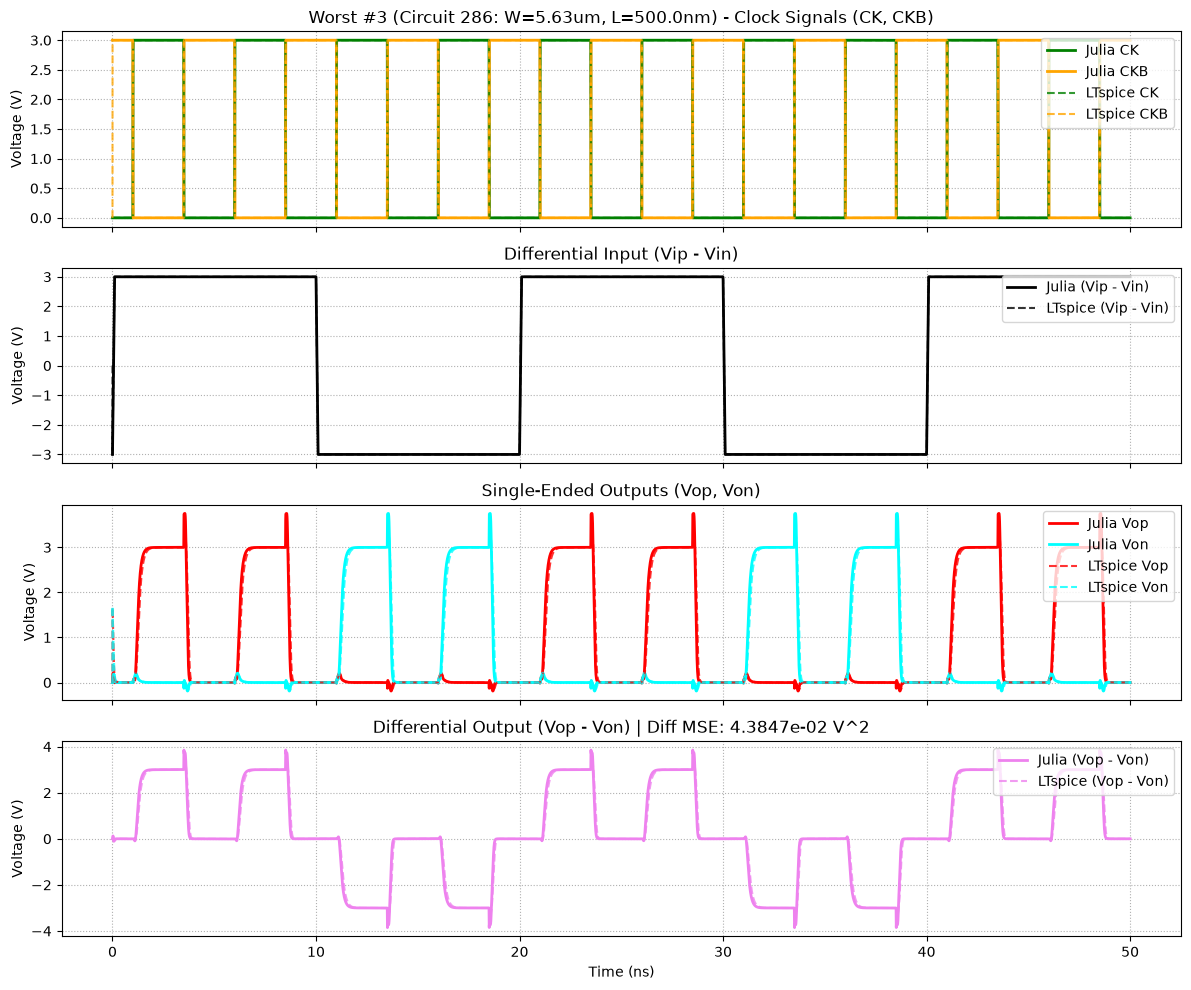


 Worst Case #4 | Circuit 296 | W = 15.89 um | L = 500.0 nm | Diff MSE = 4.3843e-02 V^2


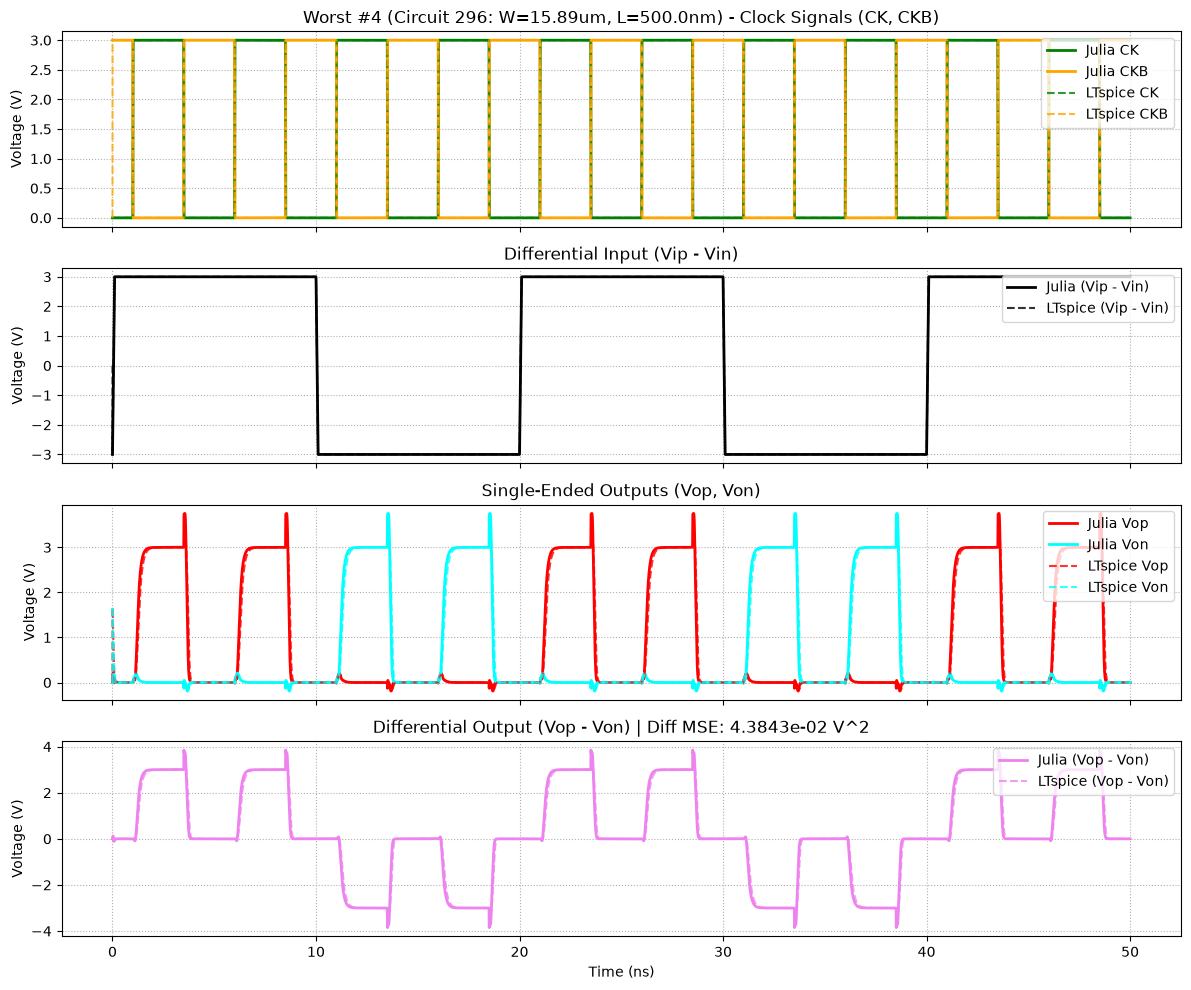


 Worst Case #5 | Circuit 292 | W = 11.79 um | L = 500.0 nm | Diff MSE = 4.3842e-02 V^2


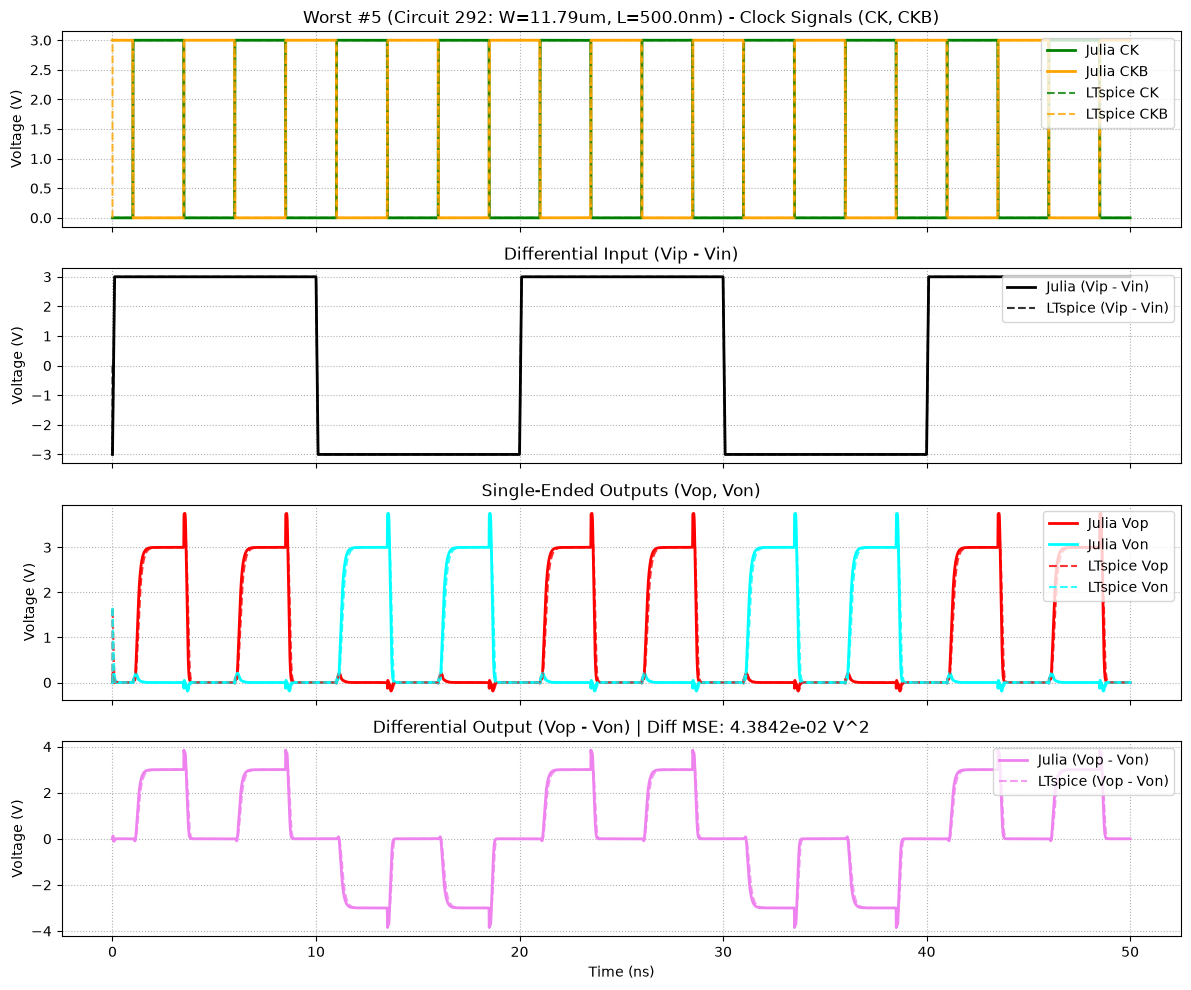


 Worst Case #6 | Circuit 298 | W = 17.95 um | L = 500.0 nm | Diff MSE = 4.3842e-02 V^2


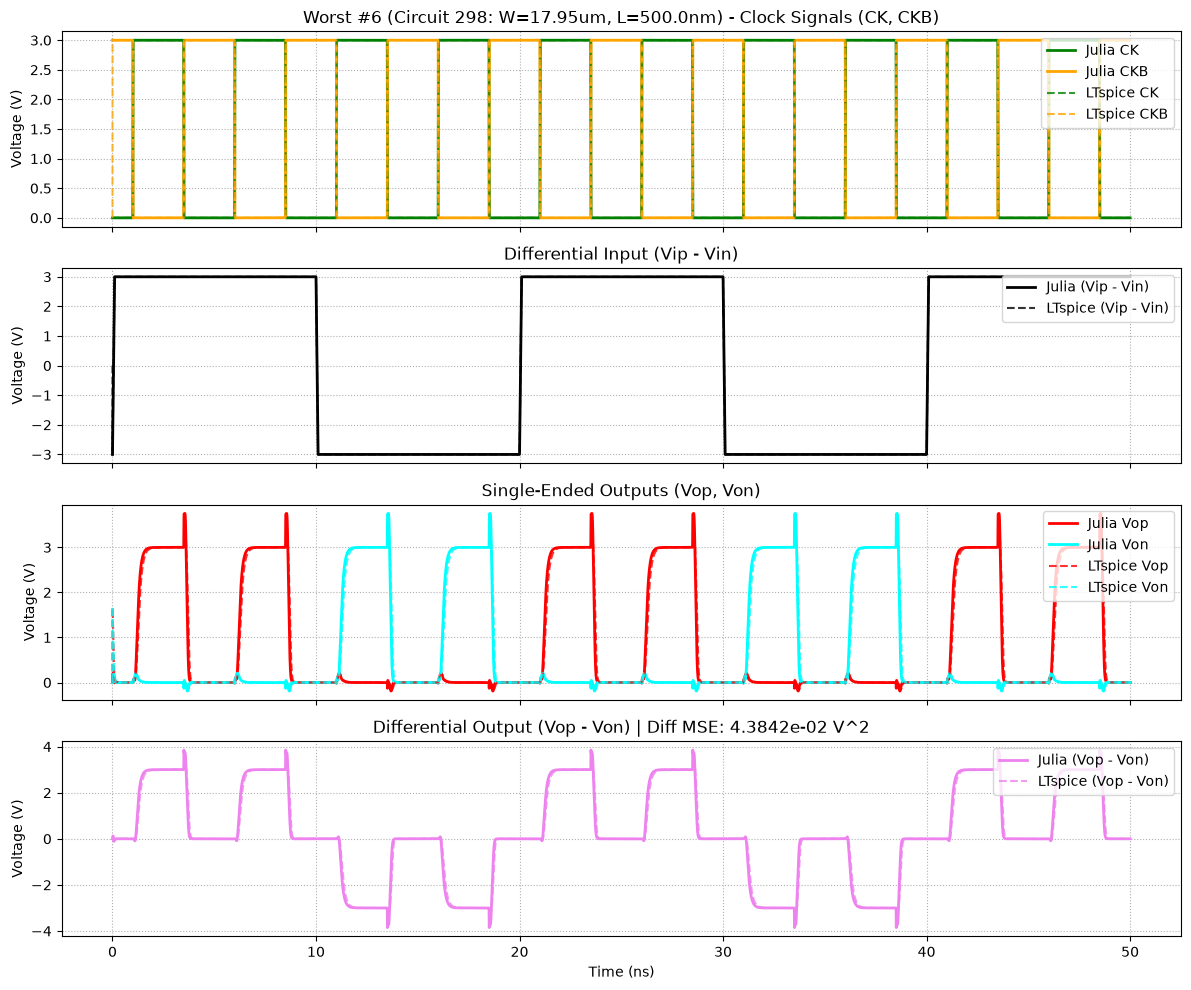


 Worst Case #7 | Circuit 289 | W = 8.71 um | L = 500.0 nm | Diff MSE = 4.3842e-02 V^2


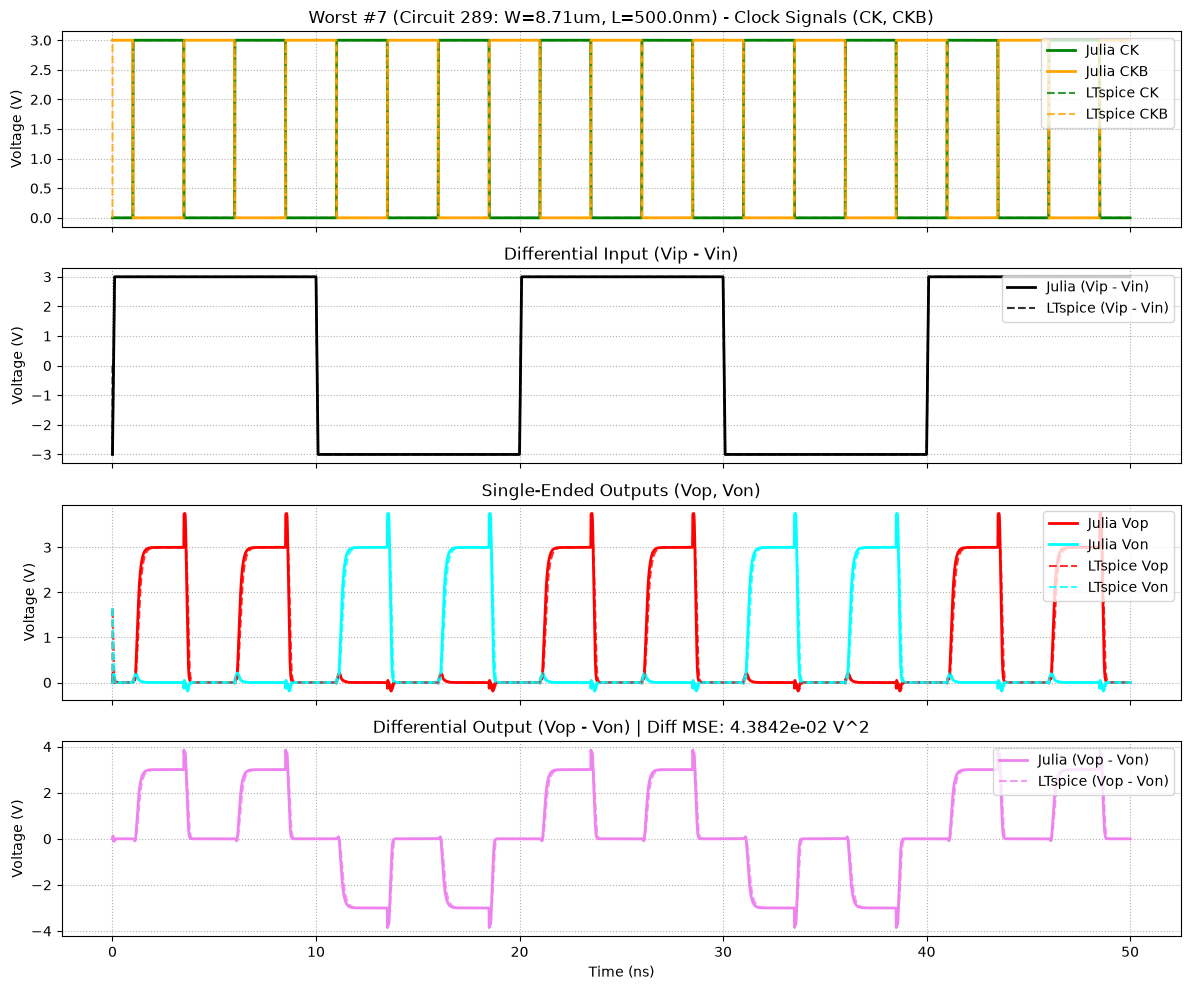


 Worst Case #8 | Circuit 295 | W = 14.87 um | L = 500.0 nm | Diff MSE = 4.3840e-02 V^2


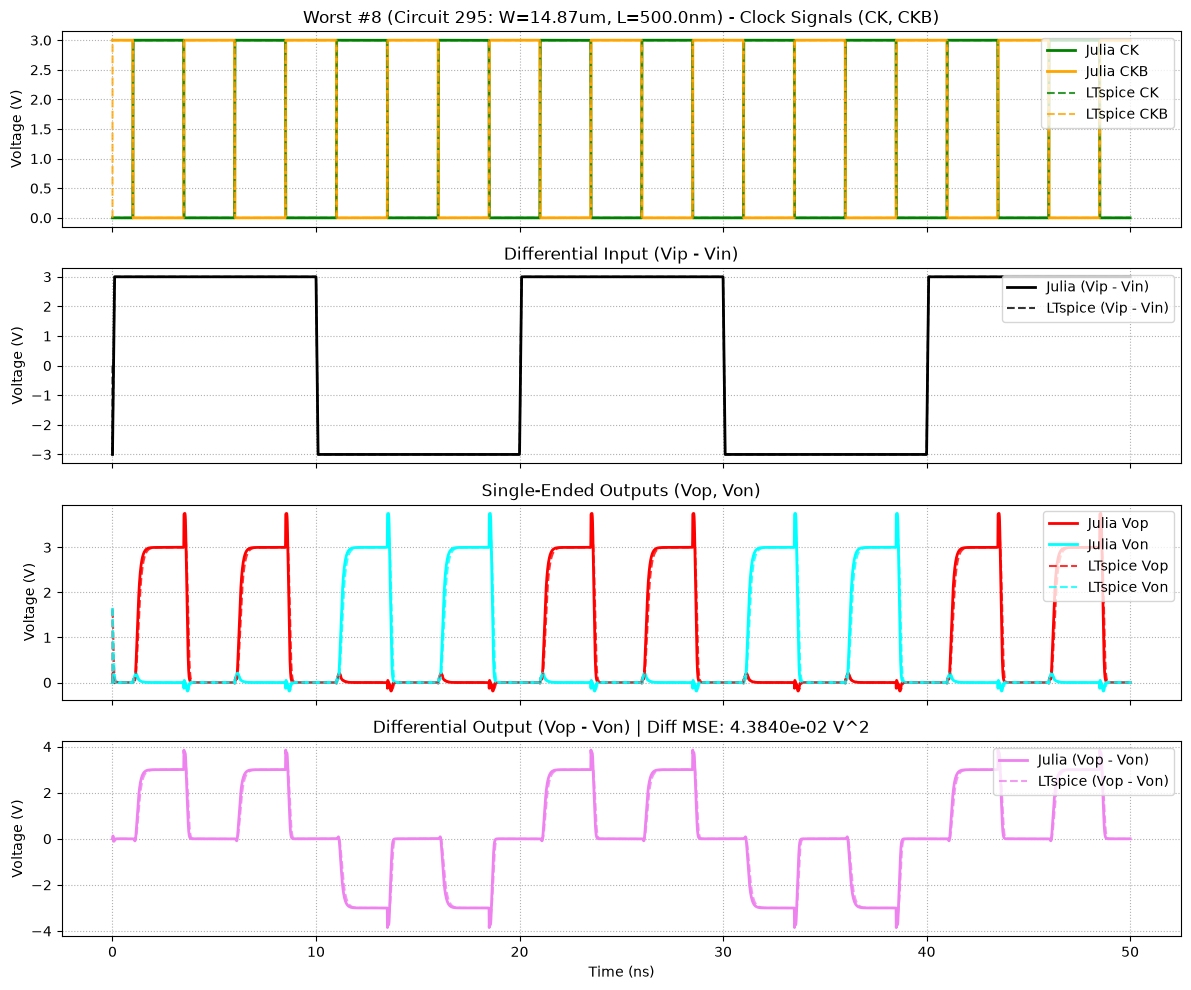


 Worst Case #9 | Circuit 291 | W = 10.76 um | L = 500.0 nm | Diff MSE = 4.3837e-02 V^2


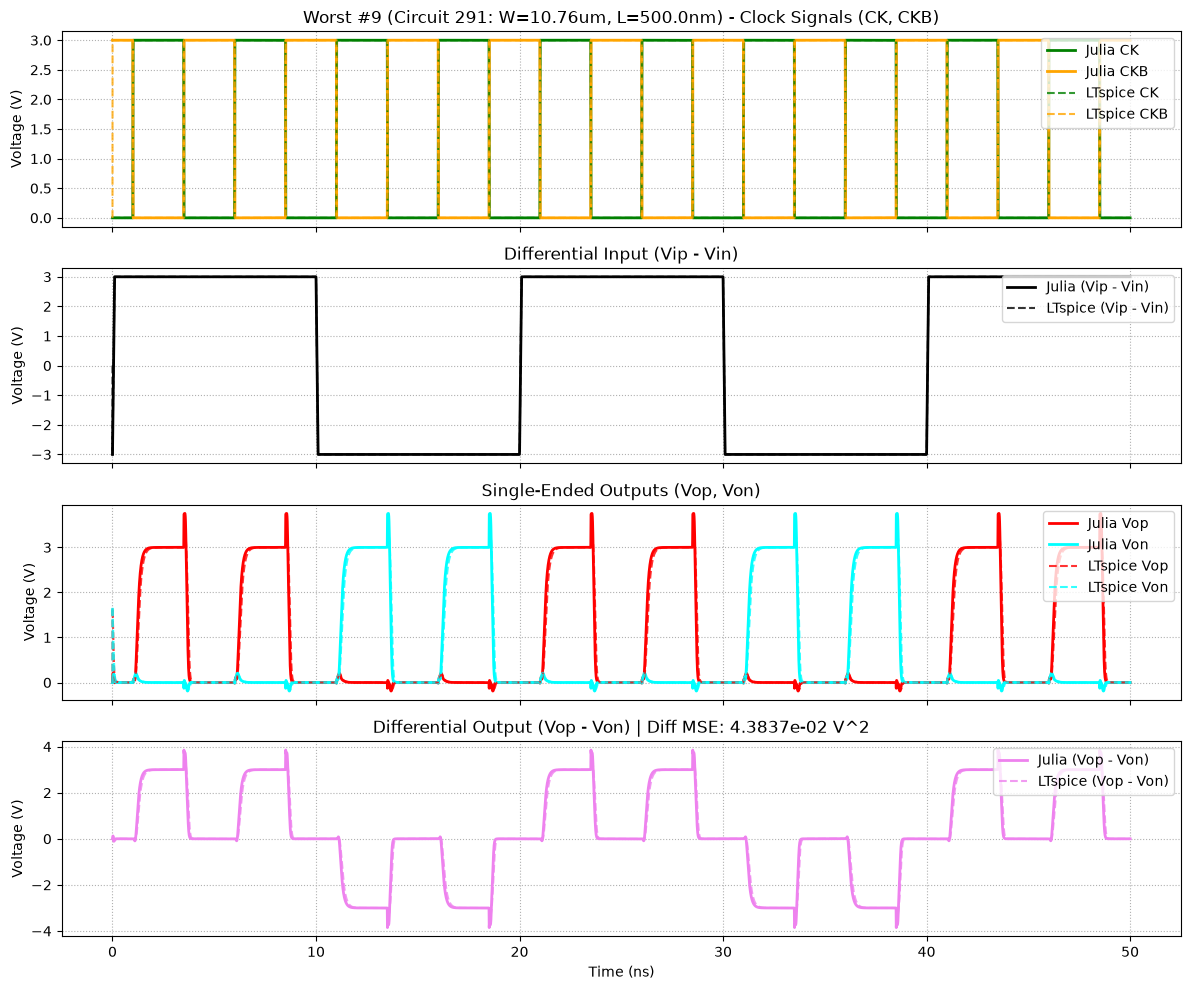


 Worst Case #10 | Circuit 282 | W = 1.53 um | L = 500.0 nm | Diff MSE = 4.3834e-02 V^2


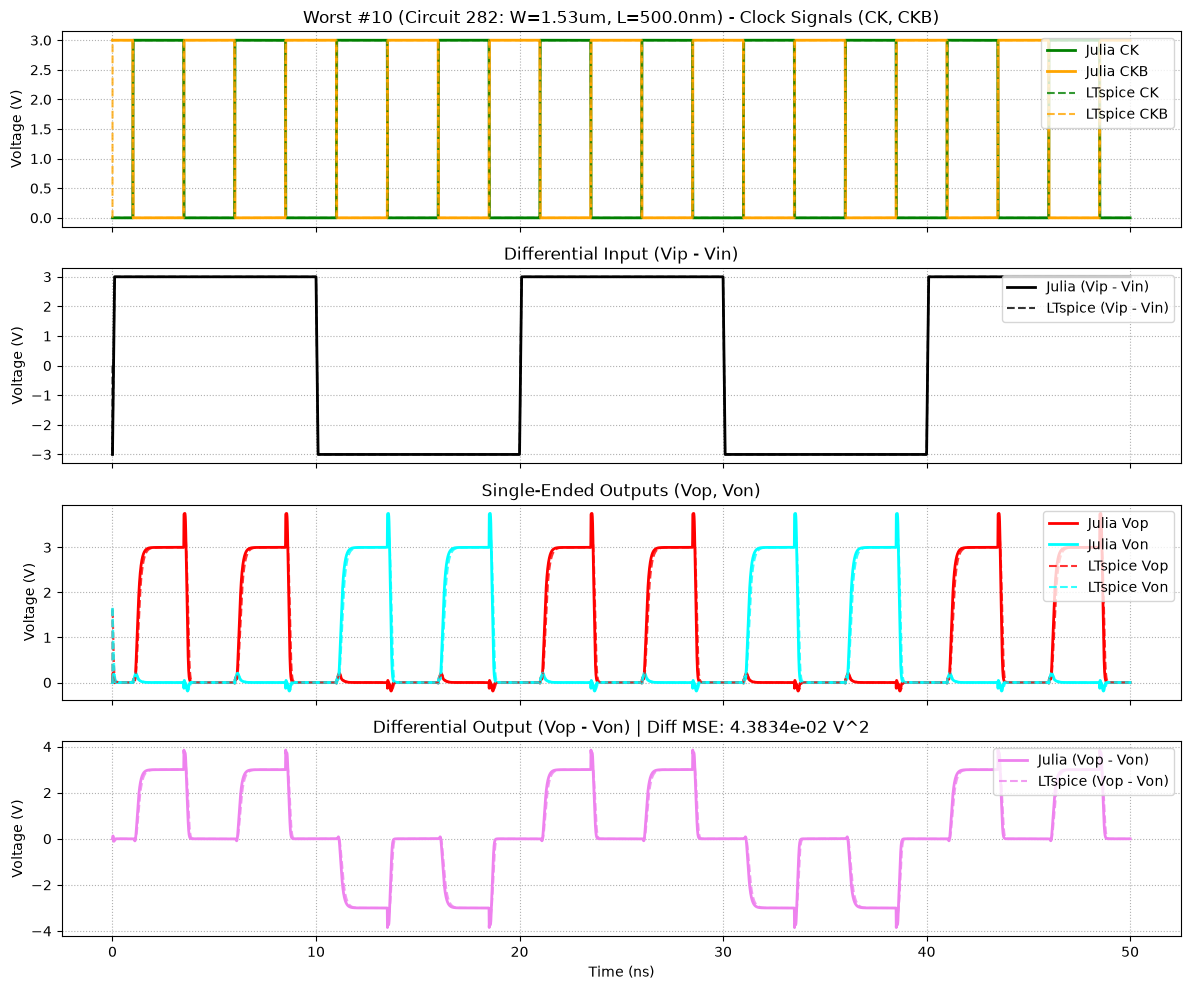


 Worst Case #11 | Circuit 281 | W = 0.50 um | L = 500.0 nm | Diff MSE = 4.3833e-02 V^2


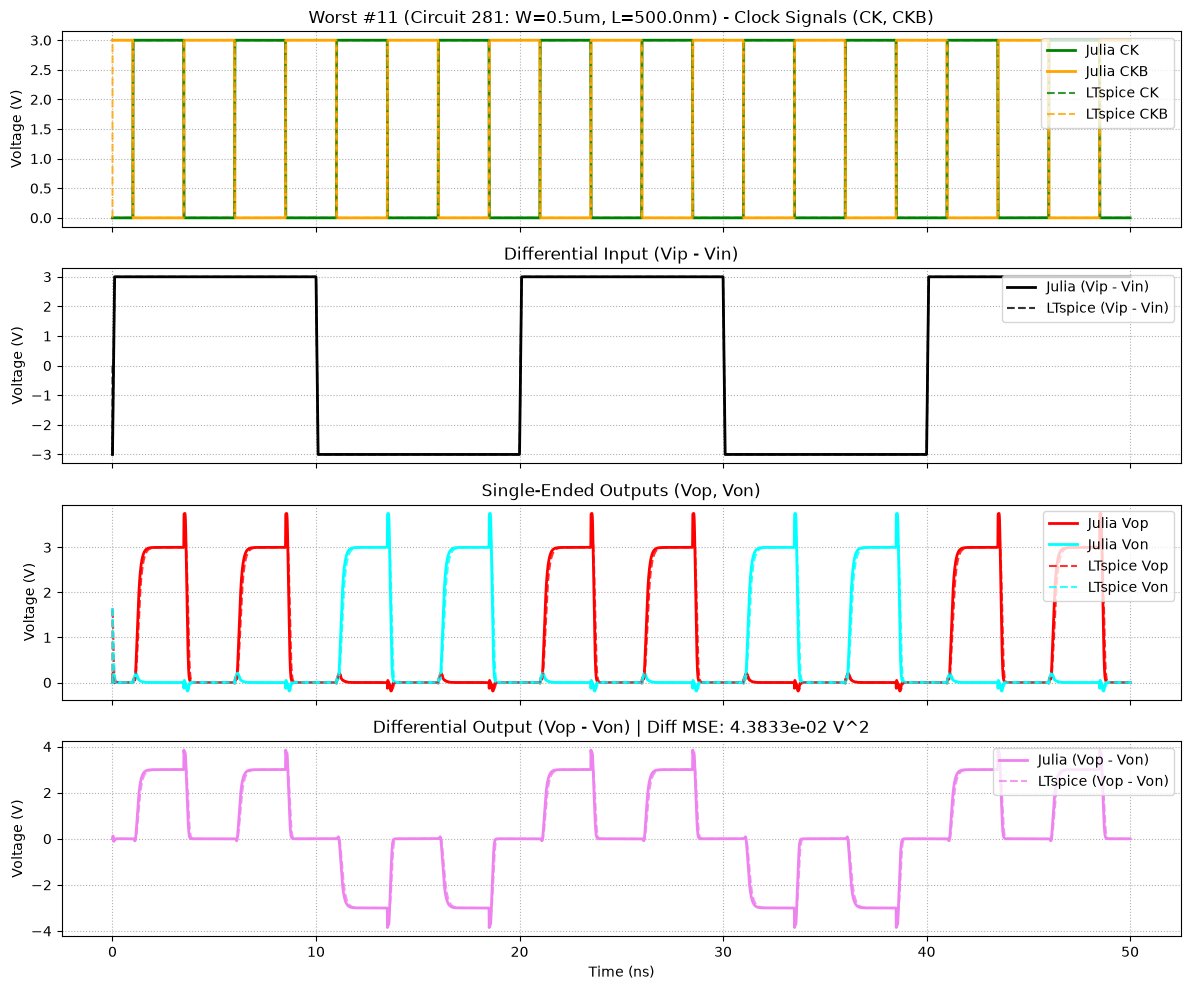


 Worst Case #12 | Circuit 285 | W = 4.61 um | L = 500.0 nm | Diff MSE = 4.3831e-02 V^2


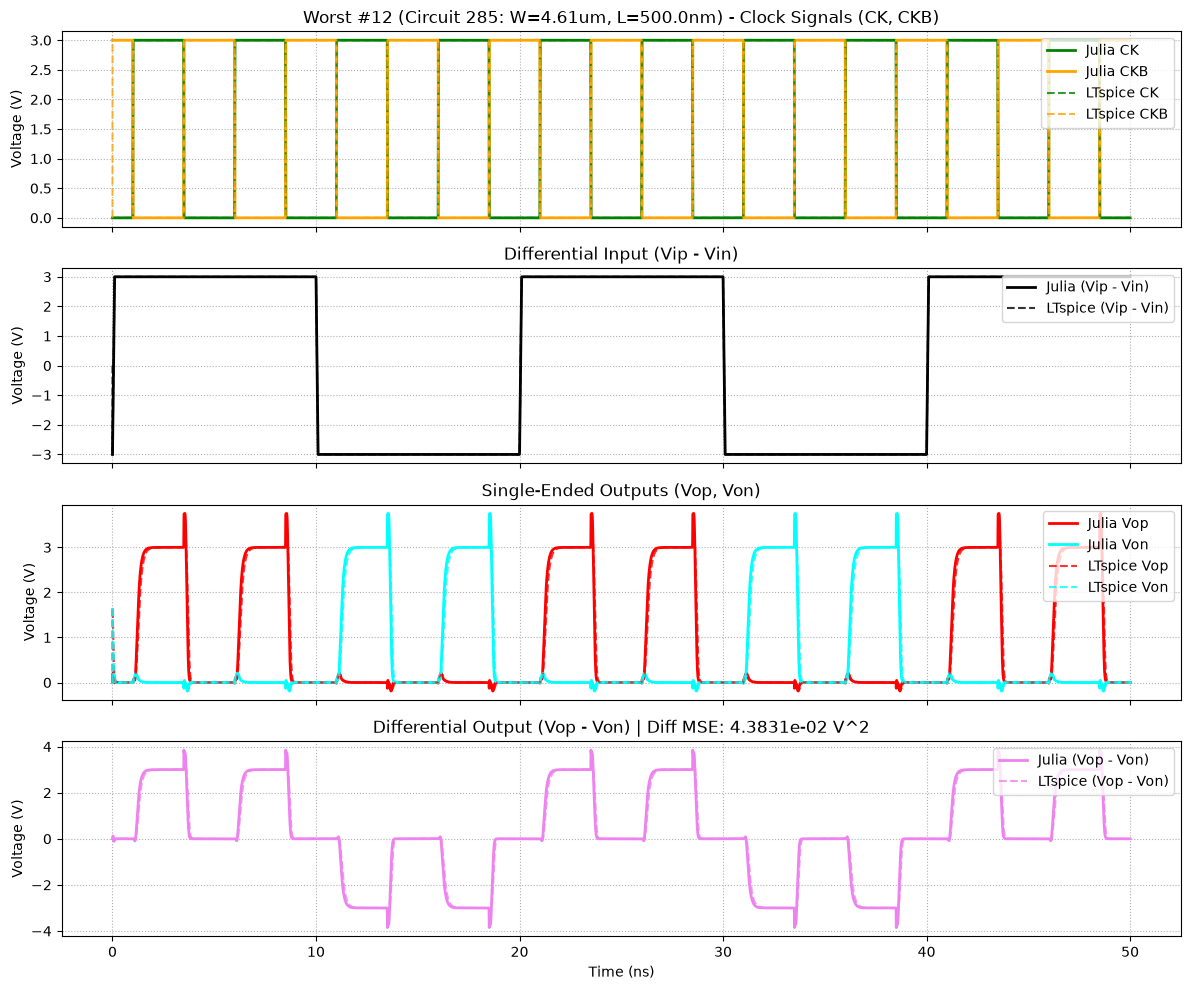


 Worst Case #13 | Circuit 288 | W = 7.68 um | L = 500.0 nm | Diff MSE = 4.3830e-02 V^2


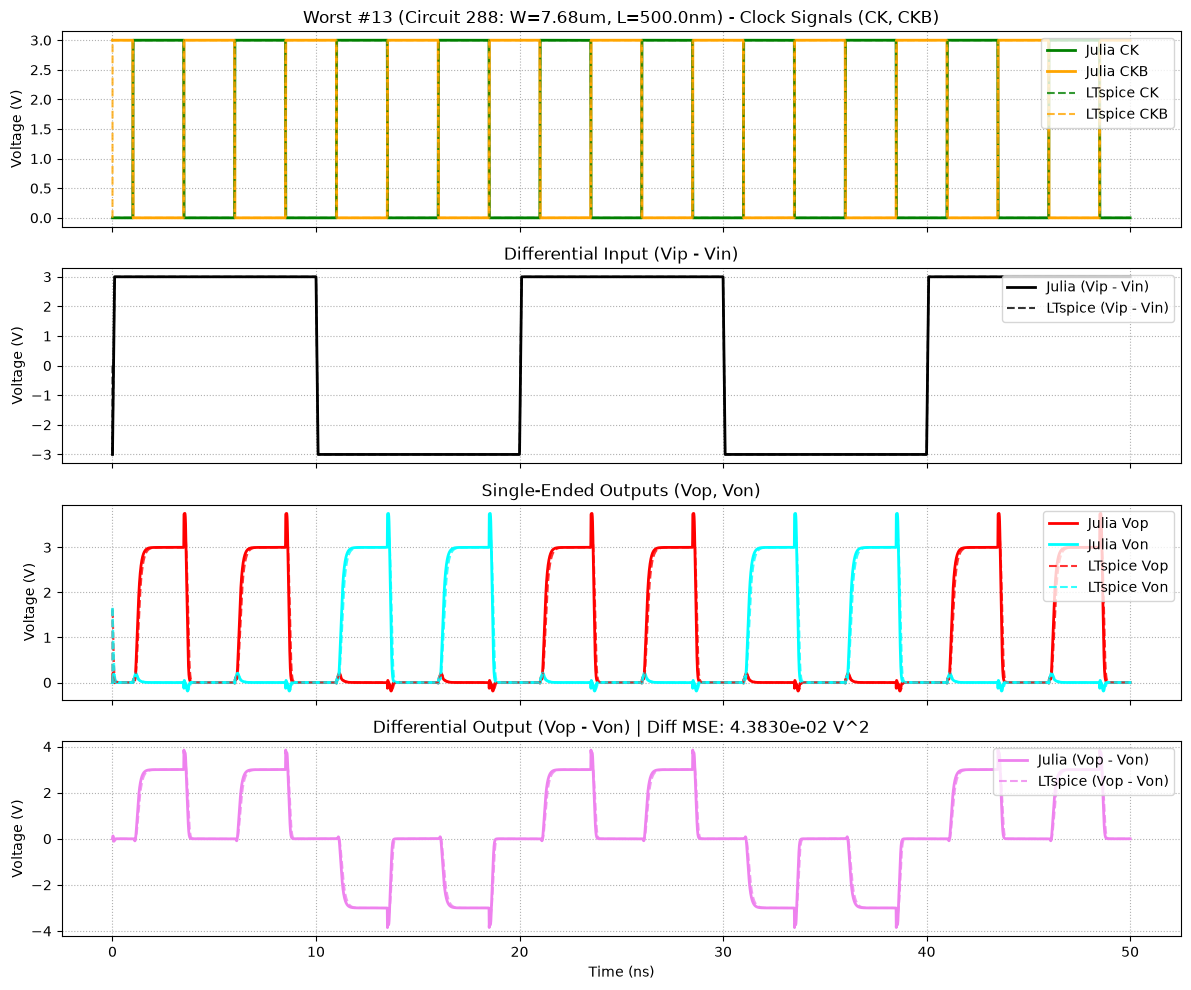


 Worst Case #14 | Circuit 283 | W = 2.55 um | L = 500.0 nm | Diff MSE = 4.3830e-02 V^2


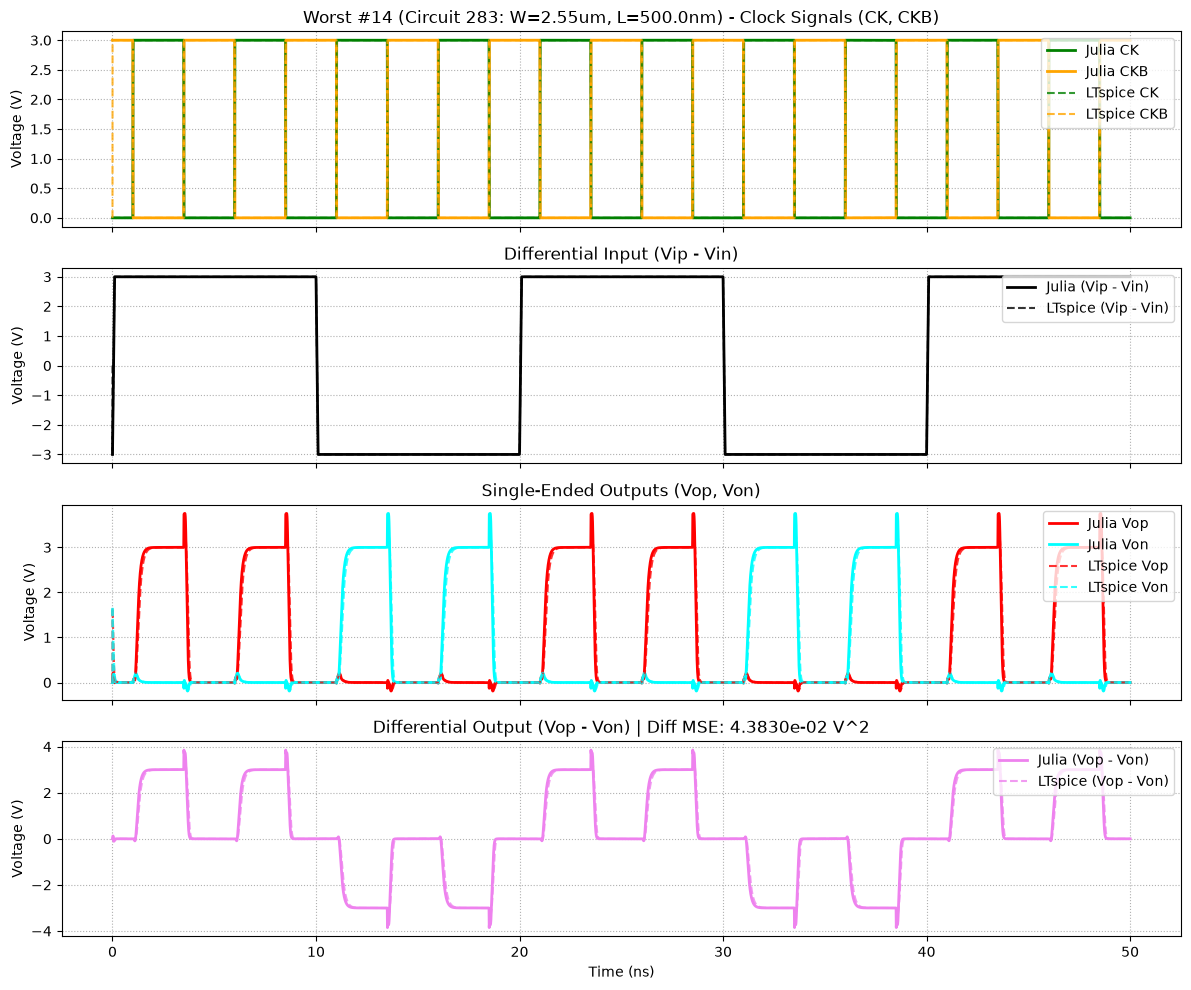


 Worst Case #15 | Circuit 290 | W = 9.74 um | L = 500.0 nm | Diff MSE = 4.3830e-02 V^2


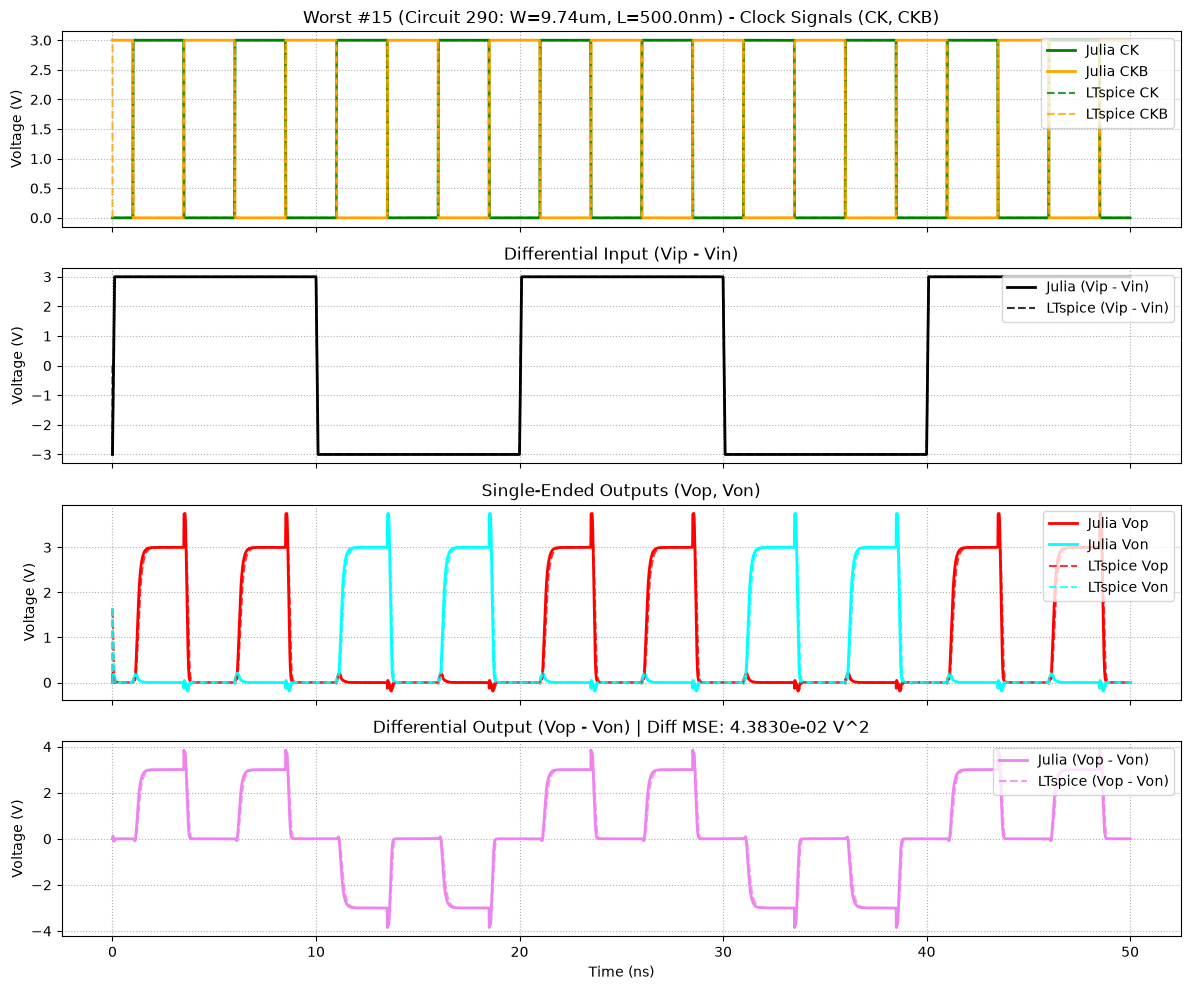


 Worst Case #16 | Circuit 294 | W = 13.84 um | L = 500.0 nm | Diff MSE = 4.3826e-02 V^2


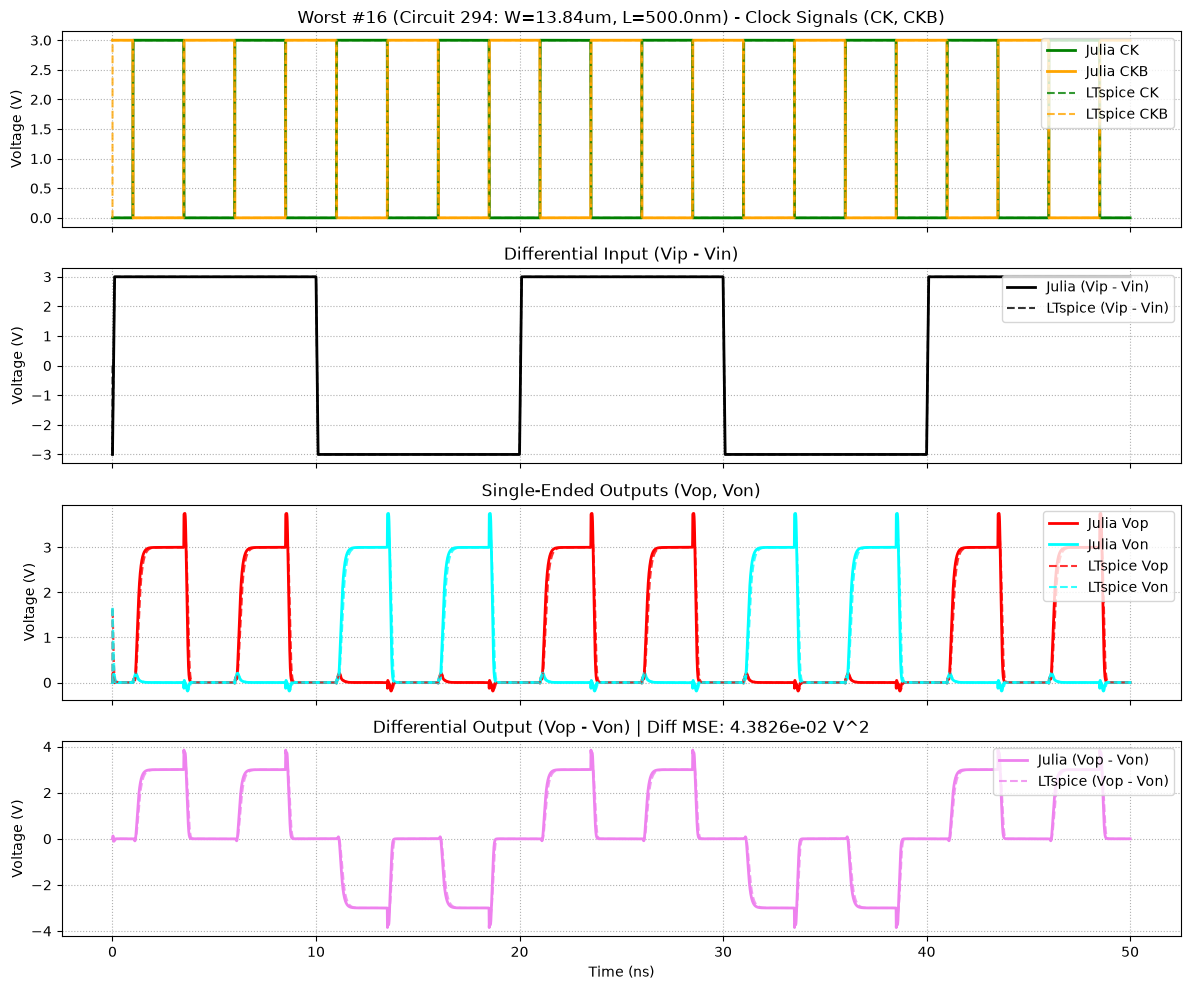


 Worst Case #17 | Circuit 300 | W = 20.00 um | L = 500.0 nm | Diff MSE = 4.3826e-02 V^2


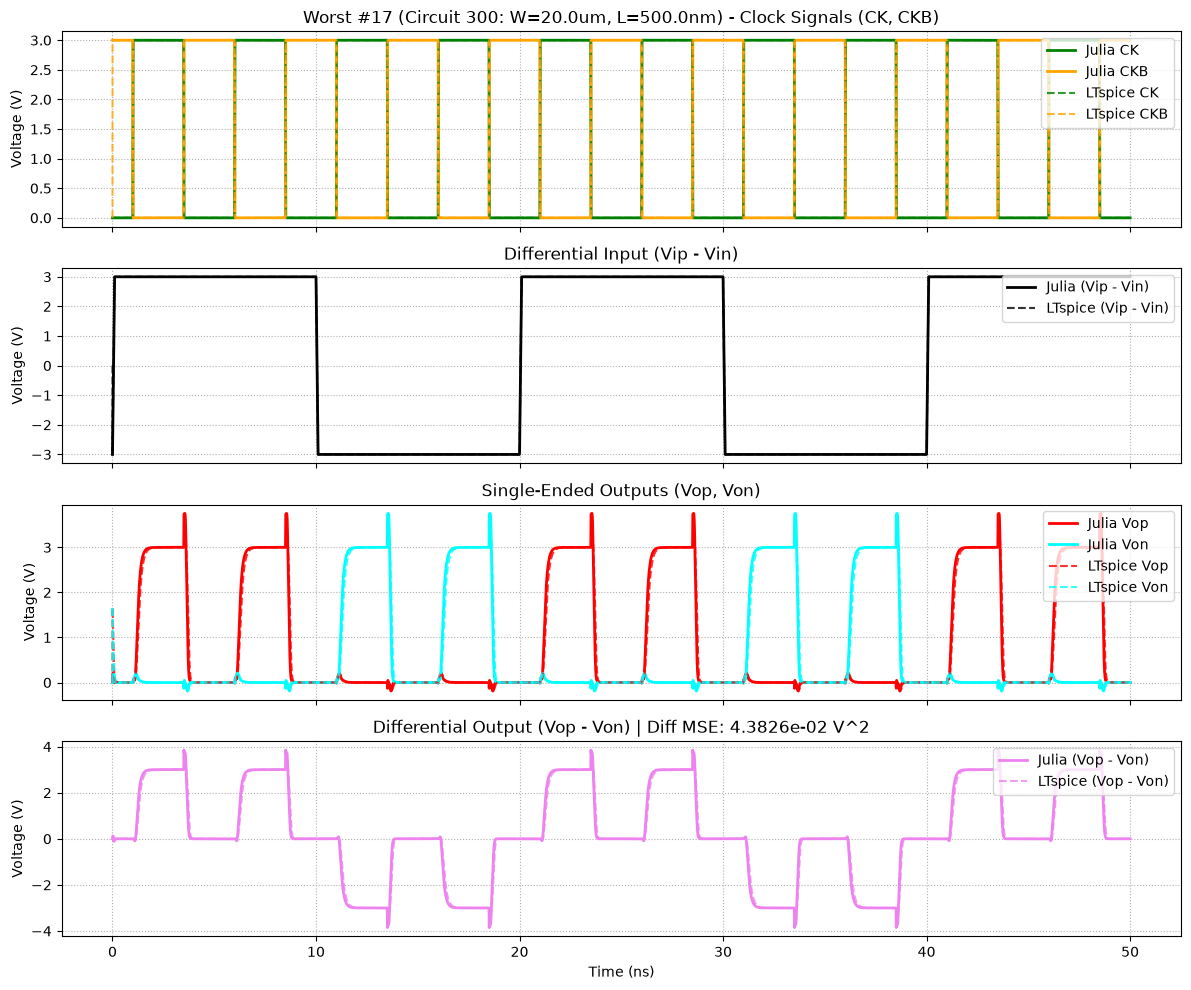


 Worst Case #18 | Circuit 293 | W = 12.82 um | L = 500.0 nm | Diff MSE = 4.3826e-02 V^2


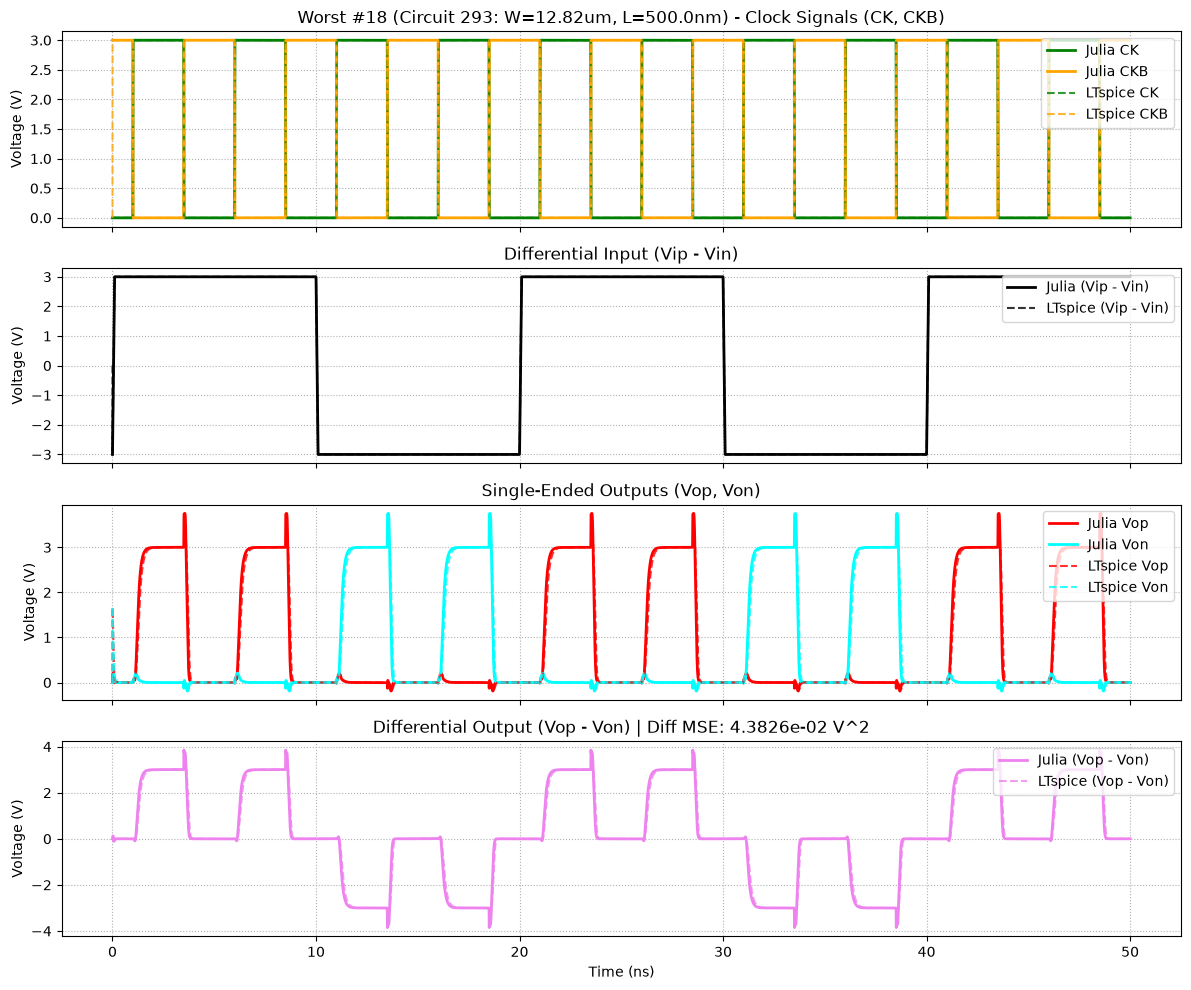


 Worst Case #19 | Circuit 299 | W = 18.97 um | L = 500.0 nm | Diff MSE = 4.3821e-02 V^2


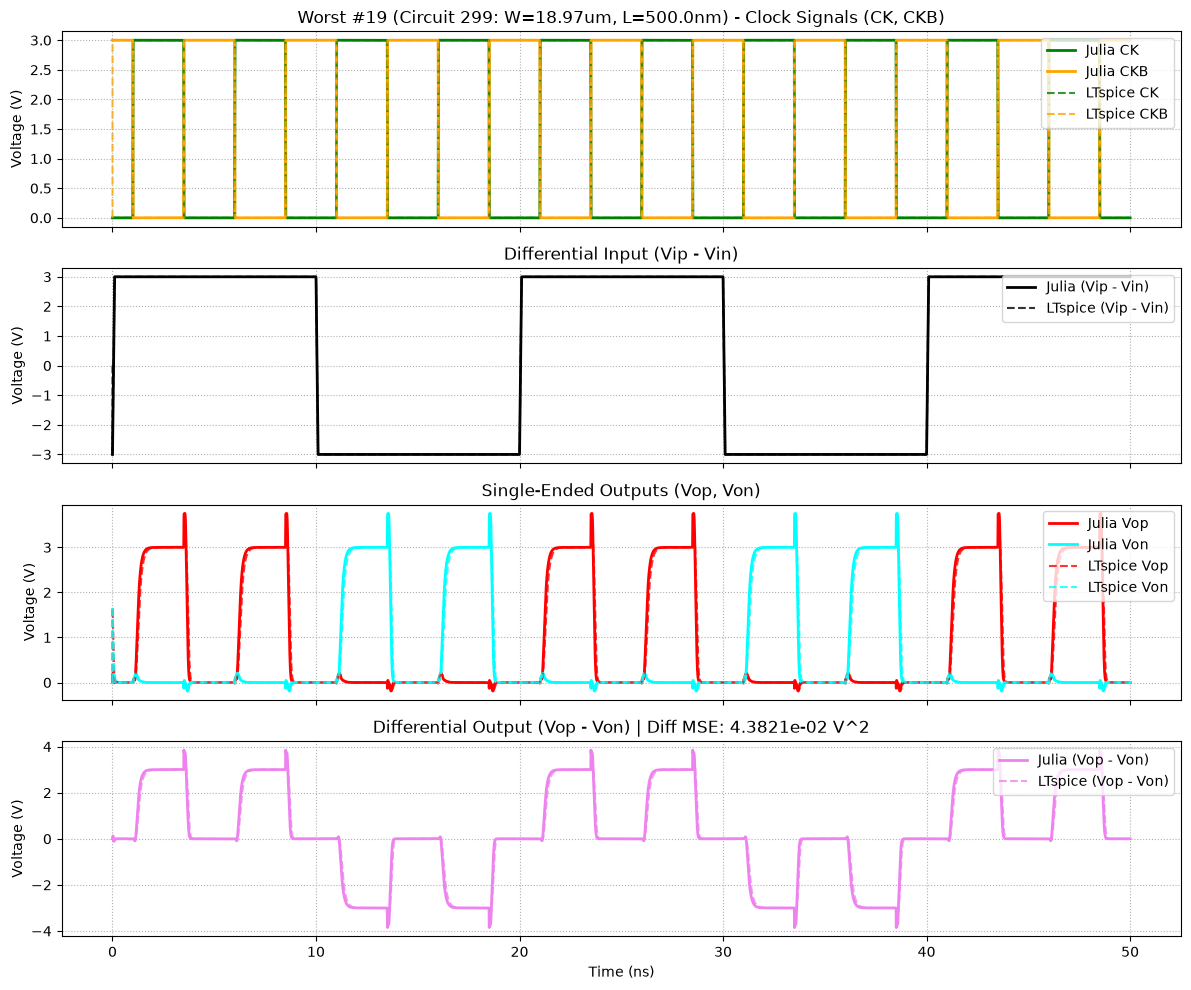


 Worst Case #20 | Circuit 284 | W = 3.58 um | L = 500.0 nm | Diff MSE = 4.3820e-02 V^2


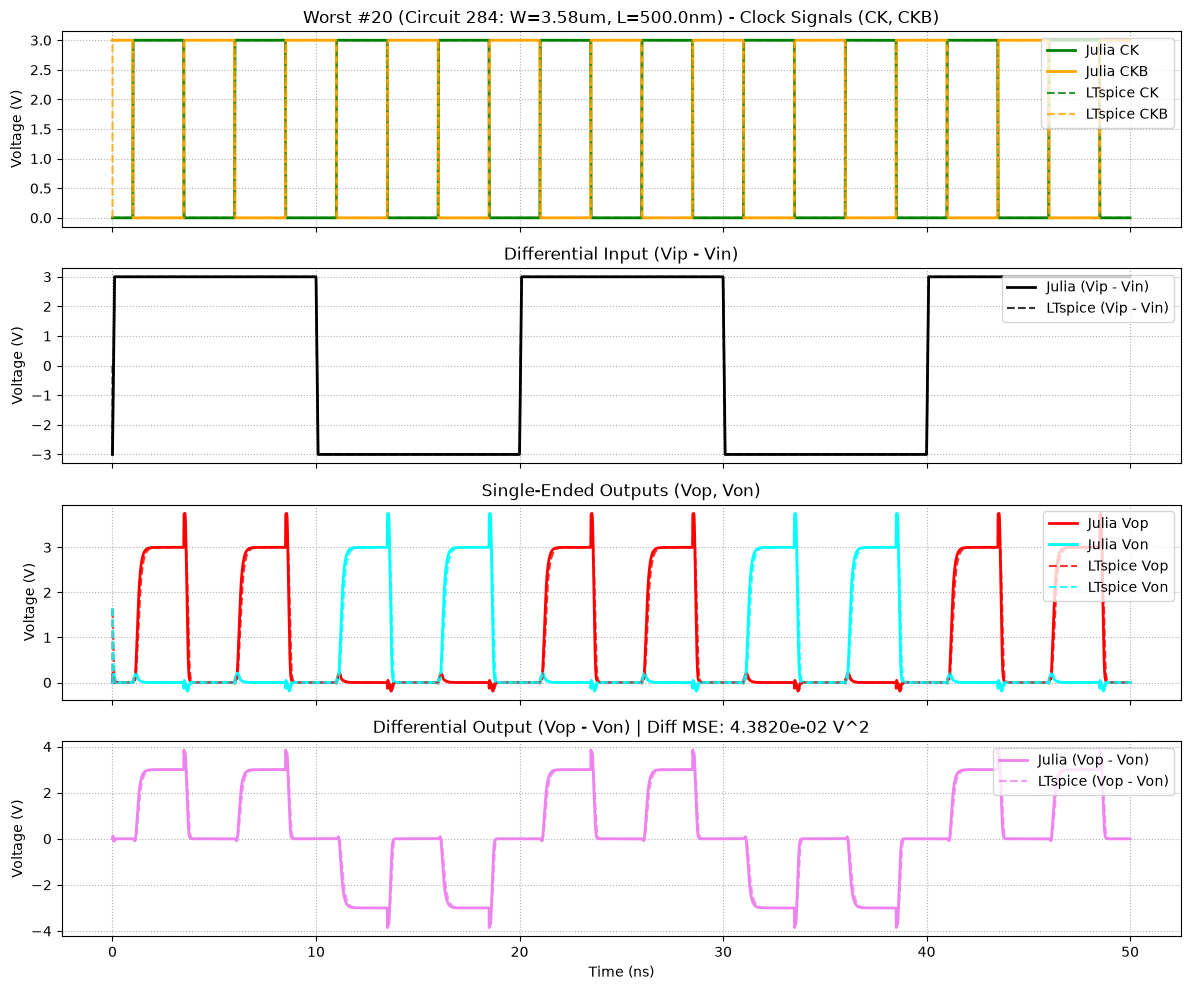

In [2]:
# 0. Set Python Environment
ENV["JULIA_PYTHONCALL_EXE"] = "C:\\Users\\mohamed\\.conda\\envs\\Thesis_Optimizer_Sandbox_Copy\\python.exe"

using Printf
using StaticArrays
using PythonCall
using Random
using JLD2
using Interpolations
using Statistics
using Base.Threads

# ==============================================================================
# 1. Call the Surrogate definitions and the simulator Engine
# ==============================================================================
# 1. Load technology model definitions
include("C:\\Users\\mohamed\\Desktop\\ML\\CAD_projects\\Netlists\\GF_180nm_tech_work\\project\\New_Sim_tests\\Allah_help_me2\\Allah_Save_me\\New folder\\system\\Julia_GSim\\Vector_Sim_Engine\\Surrogate_definitions.jl")

# 2. Load the Engine (choose Static for small circuits or Sparse for large circuits)
include("C:\\Users\\mohamed\\Desktop\\ML\\CAD_projects\\Netlists\\GF_180nm_tech_work\\project\\New_Sim_tests\\Allah_help_me2\\Allah_Save_me\\New folder\\system\\Julia_GSim\\Vector_Sim_Engine\\Static_Sim.jl")


# ==============================================================================
# 2. LTSPICE VERIFICATION GROUND TRUTH (Wref = 0.5um, SWEPT MULTIPLIERS)
# ==============================================================================
g = pydict()
pyexec(raw"""
import os, subprocess, numpy as np
from PyLTSpice import RawRead

def run_ltspice_strongarm_tran(L_val, m3, m0, m2, m1, m4, m11, m8, m6, m7, m5, m9, m10, BASE_DIR='.'):
    os.makedirs(BASE_DIR, exist_ok=True)
    LTSPICE_PATH = r"C:\Users\Mohamed\AppData\Local\Programs\ADI\LTspice\LTspice.exe"
    
    netlist = f'''* Double Tail Strong-Arm Latch Comparator
.inc cmos_tt.txt
.op
.tran 0 50n 0 10p uic
.options plotwinsize=0

* Power Supply
V1 vdd 0 3

* ==========================================
* CLOCK SOURCES
* Period=5ns, Delay=1ns, Tr/Tf=10ps, PulseWidth=2.49ns
* ==========================================
Vck CK 0 PULSE(0 3 1n 10p 10p 2.49n 5n)
Vckb CKB 0 PULSE(3 0 1n 10p 10p 2.49n 5n)

* ==========================================
* DATA INPUT SOURCES (VIP, VIN)
* Modeled as alternating bit streams (10ns bit period, Tr/Tf=100ps)
* ==========================================
Vvip VIP 0 PULSE(0 3 0n 100p 100p 9.9n 20n)
Vvin VIN 0 PULSE(3 0 0n 100p 100p 9.9n 20n)

* ==========================================
* STAGE 1: PRE-AMPLIFIER (FIRST TAIL)
* Wref = 0.5um for all devices, swept via multipliers
* ==========================================
* Tail Current Sink
M3 tail1 CK 0 0 nmos_3p3 w=0.5u l={L_val} m={m3}

* Differential Input Pair
M0 VYN VIP tail1 0 nmos_3p3 w=0.5u l={L_val} m={m0}
M2 VYP VIN tail1 0 nmos_3p3 w=0.5u l={L_val} m={m2}

* Pre-charge PMOS
M1 VYN CK vdd vdd pmos_3p3 w=0.5u l={L_val} m={m1}
M4 VYP CK vdd vdd pmos_3p3 w=0.5u l={L_val} m={m4}

* ==========================================
* STAGE 2: LATCH (SECOND TAIL)
* ==========================================
* Tail Current Source
M11 tail2 CKB vdd vdd pmos_3p3 w=0.5u l={L_val} m={m11}

* Cross-Coupled PMOS Pair
M8 VON VOP tail2 vdd pmos_3p3 w=0.5u l={L_val} m={m8}
M6 VOP VON tail2 vdd pmos_3p3 w=0.5u l={L_val} m={m6}

* Cross-Coupled NMOS Pair
M7 VON VOP 0 0 nmos_3p3 w=0.5u l={L_val} m={m7}
M5 VOP VON 0 0 nmos_3p3 w=0.5u l={L_val} m={m5}

* Latch Input NMOS (Fed by Stage 1 outputs)
M9  VON VYP 0 0 nmos_3p3 w=0.5u l={L_val} m={m9}
M10 VOP VYN 0 0 nmos_3p3 w=0.5u l={L_val} m={m10}

.model NMOS NMOS
.model PMOS PMOS
.lib {os.path.join(os.environ.get('LOCALAPPDATA', ''), 'LTspice', 'lib', 'cmp', 'standard.mos')}
.end
'''
    sp_path = os.path.join(BASE_DIR, "tran_test_strongarm.sp")
    raw_path = os.path.join(BASE_DIR, "tran_test_strongarm.raw")
    
    if os.path.exists(raw_path):
        os.remove(raw_path)
        
    with open(sp_path, 'w', encoding='utf-8') as f:
        f.write(netlist)
        
    subprocess.run([LTSPICE_PATH, "-b", "-run", sp_path], cwd=BASE_DIR, capture_output=True)
    raw = RawRead(raw_path)
    t = raw.get_trace("time").get_wave(0)
    ck = raw.get_trace("V(ck)").get_wave(0)
    ckb = raw.get_trace("V(ckb)").get_wave(0)
    vip = raw.get_trace("V(vip)").get_wave(0)
    vin = raw.get_trace("V(vin)").get_wave(0)
    vop = raw.get_trace("V(vop)").get_wave(0)
    von = raw.get_trace("V(von)").get_wave(0)
    
    return t, ck, ckb, vip, vin, vop, von
""", g)
run_ltspice_strongarm_tran = g["run_ltspice_strongarm_tran"]

# ==============================================================================
# 3. CIRCUIT DEFINITIONS & 300-BATCH SETUP
# ==============================================================================
struct CircuitParams
    W_val::Float64
    L_val::Float64
    m3::Float64
    m0::Float64
    m2::Float64
    m1::Float64
    m4::Float64
    m11::Float64
    m8::Float64
    m6::Float64
    m7::Float64
    m5::Float64
    m9::Float64
    m10::Float64
end

W_arr = range(0.5e-6, stop=20.0e-6, length=20)
L_arr = range(300e-9, stop=500e-9, length=15)
combinations = vec(collect(Iterators.product(W_arr, L_arr)))
N = length(combinations) # Exactly 300 circuits

circuits = Vector{CircuitParams}(undef, N)
for i in 1:N
    W_i, L_i = combinations[i]
    s_W = W_i / 0.5e-6 # Normalization to 0.5um base width
    circuits[i] = CircuitParams(
        W_i, L_i,
        2.0 * s_W,  # m3
        6.0 * s_W,  # m0
        6.0 * s_W,  # m2
        8.0 * s_W,  # m1
        8.0 * s_W,  # m4
        2.0 * s_W,  # m11
        2.0 * s_W,  # m8
        2.0 * s_W,  # m6
        1.0 * s_W,  # m7
        1.0 * s_W,  # m5
        1.0 * s_W,  # m9
        1.0 * s_W   # m10
    )
end

println("\n====================================================================")
println(" TRANSIENT BATCH EVALUATION: $(N) CIRCUITS (DOUBLE TAIL STRONG-ARM LATCH)")
println("====================================================================")

sim_tran = JuliaGSim(surrogate_model)
add_vsource!(sim_tran, "V1", "vdd", "0", 3.0)

# Clock and Data Pulse definitions matching LTspice
pulse_ck = make_pulse(0.0, 3.0, 1e-9, 10e-12, 10e-12, 2.49e-9, 5e-9)
pulse_ckb = make_pulse(3.0, 0.0, 1e-9, 10e-12, 10e-12, 2.49e-9, 5e-9)
pulse_vip = make_pulse(0.0, 3.0, 0.0, 100e-12, 100e-12, 9.9e-9, 20e-9)
pulse_vin = make_pulse(3.0, 0.0, 0.0, 100e-12, 100e-12, 9.9e-9, 20e-9)

add_vsource!(sim_tran, "Vck", "CK", "0", pulse_ck)
add_vsource!(sim_tran, "Vckb", "CKB", "0", pulse_ckb)
add_vsource!(sim_tran, "Vvip", "VIP", "0", pulse_vip)
add_vsource!(sim_tran, "Vvin", "VIN", "0", pulse_vin)

# STAGE 1: PRE-AMPLIFIER (FIRST TAIL)
add_nmos!(sim_tran, "M3", d="tail1", g="CK", s="0", b="0", M=:m3, L=:L_val)
add_nmos!(sim_tran, "M0", d="VYN", g="VIP", s="tail1", b="0", M=:m0, L=:L_val)
add_nmos!(sim_tran, "M2", d="VYP", g="VIN", s="tail1", b="0", M=:m2, L=:L_val)
add_pmos!(sim_tran, "M1", d="VYN", g="CK", s="vdd", b="vdd", M=:m1, L=:L_val)
add_pmos!(sim_tran, "M4", d="VYP", g="CK", s="vdd", b="vdd", M=:m4, L=:L_val)

# STAGE 2: LATCH (SECOND TAIL)
add_pmos!(sim_tran, "M11", d="tail2", g="CKB", s="vdd", b="vdd", M=:m11, L=:L_val)
add_pmos!(sim_tran, "M8", d="VON", g="VOP", s="tail2", b="vdd", M=:m8, L=:L_val)
add_pmos!(sim_tran, "M6", d="VOP", g="VON", s="tail2", b="vdd", M=:m6, L=:L_val)
add_nmos!(sim_tran, "M7", d="VON", g="VOP", s="0", b="0", M=:m7, L=:L_val)
add_nmos!(sim_tran, "M5", d="VOP", g="VON", s="0", b="0", M=:m5, L=:L_val)
add_nmos!(sim_tran, "M9", d="VON", g="VYP", s="0", b="0", M=:m9, L=:L_val)
add_nmos!(sim_tran, "M10", d="VOP", g="VYN", s="0", b="0", M=:m10, L=:L_val)

compile!(sim_tran)

BASE_DIR = pwd()

# ==============================================================================
# 4. RUN JULIAGSIM (ALWAYS RUNS FRESH & OVERWRITES CACHE)
# ==============================================================================
println("\n>>> Running $(N)-Batch Transient Solves on $(nthreads()) Julia Threads...")

t_stop = 50e-9
dt_init = 10e-12
dt_max = 10e-12

results_x_hist = Vector{Matrix{Float64}}(undef, N)
results_t_hist = Vector{Vector{Float64}}(undef, N)

start_time = time()
@threads for i in 1:N
    t_hist, x_hist = solve_tran(sim_tran, circuits[i], t_stop, dt_init, uic=true, dt_max=dt_max)
    results_x_hist[i] = x_hist
    results_t_hist[i] = t_hist
end
total_time = time() - start_time

println("Julia $(N)-Circuit Transient Total Time: $(round(total_time, digits=4)) s")

# Save/overwrite fresh Julia simulation results to disk
julia_cache_file = joinpath(BASE_DIR, "julia_strongarm_cache_$(N).jld2")
@save julia_cache_file results_t_hist results_x_hist total_time
println("    Saved fresh Julia results to: $julia_cache_file")

idx_vop = findfirst(==("VOP"), sim_tran.unknown_nodes)
idx_von = findfirst(==("VON"), sim_tran.unknown_nodes)

# ==============================================================================
# 5. RUN LTSPICE BASELINE (ALWAYS RUNS FRESH & OVERWRITES CACHE)
# ==============================================================================
println("\n>>> Running LTspice baseline (Sequential)...")

spice_times = Vector{Any}(undef, N)
spice_cks   = Vector{Any}(undef, N)
spice_ckbs  = Vector{Any}(undef, N)
spice_vips  = Vector{Any}(undef, N)
spice_vins  = Vector{Any}(undef, N)
spice_vops  = Vector{Any}(undef, N)
spice_vons  = Vector{Any}(undef, N)

start_spice = time()
for i in 1:N
    c = circuits[i]
    t_lt, ck_lt, ckb_lt, vip_lt, vin_lt, vop_lt, von_lt = run_ltspice_strongarm_tran(
        c.L_val, c.m3, c.m0, c.m2, c.m1, c.m4, c.m11, c.m8, c.m6, c.m7, c.m5, c.m9, c.m10, BASE_DIR
    )
    spice_times[i] = pyconvert(Array, t_lt)
    spice_cks[i]   = pyconvert(Array, ck_lt)
    spice_ckbs[i]  = pyconvert(Array, ckb_lt)
    spice_vips[i]  = pyconvert(Array, vip_lt)
    spice_vins[i]  = pyconvert(Array, vin_lt)
    spice_vops[i]  = pyconvert(Array, vop_lt)
    spice_vons[i]  = pyconvert(Array, von_lt)
    if i % 30 == 0; println("    LTspice progress: $i/$N circuits done..."); end
end
spice_time = time() - start_spice

println("LTspice Total Time: $(round(spice_time, digits=4)) s")

# Save/overwrite fresh LTspice simulation results to disk
spice_cache_file = joinpath(BASE_DIR, "ltspice_strongarm_cache_$(N).jld2")
@save spice_cache_file spice_times spice_cks spice_ckbs spice_vips spice_vins spice_vops spice_vons spice_time
println("    Saved fresh LTspice results to: $spice_cache_file")

speedup = spice_time / total_time
println("\n======================================================================")
println(" 🚀 TRANSIENT PERFORMANCE SUMMARY (STRONG-ARM LATCH)")
println("======================================================================")
@printf(" JuliaGSim Time : %.3f seconds\n", total_time)
@printf(" LTspice Time   : %.3f seconds\n", spice_time)
@printf(" Speedup Factor : %.2fx faster than LTspice!\n", speedup)
println("======================================================================\n")

# ==============================================================================
# 6. MSE EXTRACTION & FULL 300-CIRCUIT COMPARISON TABLE
# ==============================================================================
mse_vop_arr  = zeros(N)
mse_von_arr  = zeros(N)
mse_diff_arr = zeros(N)

for i in 1:N
    t_jl = results_t_hist[i]
    vop_jl = results_x_hist[i][idx_vop, :]
    von_jl = results_x_hist[i][idx_von, :]
    vdiff_jl = vop_jl .- von_jl

    t_sp = spice_times[i]
    vop_sp = spice_vops[i]
    von_sp = spice_vons[i]
    vdiff_sp = vop_sp .- von_sp

    interp_vop  = linear_interpolation(t_jl, vop_jl, extrapolation_bc=Line())
    interp_von  = linear_interpolation(t_jl, von_jl, extrapolation_bc=Line())
    interp_diff = linear_interpolation(t_jl, vdiff_jl, extrapolation_bc=Line())

    mse_vop_arr[i]  = mean((interp_vop.(t_sp) .- vop_sp).^2)
    mse_von_arr[i]  = mean((interp_von.(t_sp) .- von_sp).^2)
    mse_diff_arr[i] = mean((interp_diff.(t_sp) .- vdiff_sp).^2)
end

println("==========================================================================================")
println(" DETAILED CIRCUIT RESULTS (WAVEFORM MSE FOR ALL $(N) CIRCUITS)")
println("==========================================================================================\n")
@printf("%-10s | %-12s | %-12s | %-15s | %-15s | %-15s\n", "Circuit", "W (um)", "L (nm)", "MSE Vop (V^2)", "MSE Von (V^2)", "MSE Diff (V^2)")
println(repeat("-", 90))

for i in 1:N
    @printf("%-10d | %-12.2f | %-12.1f | %-15.4e | %-15.4e | %-15.4e\n", 
        i, circuits[i].W_val * 1e6, circuits[i].L_val * 1e9, 
        mse_vop_arr[i], mse_von_arr[i], mse_diff_arr[i])
end
println()

println("======================================================================")
println(" OVERALL ACCURACY STATISTICAL SUMMARY ($(N) CIRCUITS)")
println("======================================================================")
@printf(" Max Differential MSE    : %.4e V^2\n", maximum(mse_diff_arr))
@printf(" Mean Differential MSE   : %.4e V^2\n", mean(mse_diff_arr))
@printf(" Max Vop MSE             : %.4e V^2\n", maximum(mse_vop_arr))
@printf(" Mean Vop MSE            : %.4e V^2\n", mean(mse_vop_arr))
@printf(" Max Von MSE             : %.4e V^2\n", maximum(mse_von_arr))
@printf(" Mean Von MSE            : %.4e V^2\n", mean(mse_von_arr))
println("======================================================================\n")

# ==============================================================================
# 7. 4-PANE WAVEFORM PLOTS: TOP 20 CIRCUITS WITH HIGHEST MSE
# ==============================================================================
plt = pyimport("matplotlib.pyplot")

worst_order = sortperm(mse_diff_arr, rev=true)
worst_20 = worst_order[1:min(20, N)]

println("======================================================================")
println(" 4-PANE WAVEFORM PLOTS: TOP 20 CIRCUITS WITH HIGHEST DIFFERENTIAL MSE")
println("======================================================================\n")

for (rank, i) in enumerate(worst_20)
    t_jl = results_t_hist[i]
    vop_jl = results_x_hist[i][idx_vop, :]
    von_jl = results_x_hist[i][idx_von, :]

    ck_jl = [pulse_ck(t) for t in t_jl]
    ckb_jl = [pulse_ckb(t) for t in t_jl]
    vip_jl = [pulse_vip(t) for t in t_jl]
    vin_jl = [pulse_vin(t) for t in t_jl]

    t_sp = spice_times[i]
    ck_sp = spice_cks[i]
    ckb_sp = spice_ckbs[i]
    vip_sp = spice_vips[i]
    vin_sp = spice_vins[i]
    vop_sp = spice_vops[i]
    von_sp = spice_vons[i]

    println(repeat("=", 85))
    @printf(" Worst Case #%d | Circuit %d | W = %.2f um | L = %.1f nm | Diff MSE = %.4e V^2\n", 
        rank, i, circuits[i].W_val * 1e6, circuits[i].L_val * 1e9, mse_diff_arr[i])
    println(repeat("=", 85))

    fig, axs = plt.subplots(4, 1, figsize=(12, 10), sharex=true)

    # 1. (CK , CKB) from Julia (Green Solid , Orange Solid) + Ltspice (Green Dashed , Orange Dashed)
    axs[0].plot(t_jl .* 1e9, ck_jl, color="green", linestyle="-", linewidth=2.0, label="Julia CK")
    axs[0].plot(t_jl .* 1e9, ckb_jl, color="orange", linestyle="-", linewidth=2.0, label="Julia CKB")
    axs[0].plot(t_sp .* 1e9, ck_sp, color="green", linestyle="--", linewidth=1.5, alpha=0.8, label="LTspice CK")
    axs[0].plot(t_sp .* 1e9, ckb_sp, color="orange", linestyle="--", linewidth=1.5, alpha=0.8, label="LTspice CKB")
    axs[0].set_ylabel("Voltage (V)")
    axs[0].set_title("Worst #$rank (Circuit $i: W=$(round(circuits[i].W_val*1e6, digits=2))um, L=$(round(circuits[i].L_val*1e9, digits=1))nm) - Clock Signals (CK, CKB)")
    axs[0].legend(loc="upper right")
    axs[0].grid(true, which="both", ls=":")

    # 2. (vip - vin) from Julia (Black Solid) + Ltspice (Black Dashed)
    axs[1].plot(t_jl .* 1e9, vip_jl .- vin_jl, color="black", linestyle="-", linewidth=2.0, label="Julia (Vip - Vin)")
    axs[1].plot(t_sp .* 1e9, vip_sp .- vin_sp, color="black", linestyle="--", linewidth=1.5, alpha=0.8, label="LTspice (Vip - Vin)")
    axs[1].set_ylabel("Voltage (V)")
    axs[1].set_title("Differential Input (Vip - Vin)")
    axs[1].legend(loc="upper right")
    axs[1].grid(true, which="both", ls=":")

    # 3. (vop , von) from Julia (Red Solid , Cyan Solid) + Ltspice (Red Dashed , Cyan Dashed)
    axs[2].plot(t_jl .* 1e9, vop_jl, color="red", linestyle="-", linewidth=2.0, label="Julia Vop")
    axs[2].plot(t_jl .* 1e9, von_jl, color="cyan", linestyle="-", linewidth=2.0, label="Julia Von")
    axs[2].plot(t_sp .* 1e9, vop_sp, color="red", linestyle="--", linewidth=1.5, alpha=0.8, label="LTspice Vop")
    axs[2].plot(t_sp .* 1e9, von_sp, color="cyan", linestyle="--", linewidth=1.5, alpha=0.8, label="LTspice Von")
    axs[2].set_ylabel("Voltage (V)")
    axs[2].set_title("Single-Ended Outputs (Vop, Von)")
    axs[2].legend(loc="upper right")
    axs[2].grid(true, which="both", ls=":")

    # 4. (vop-von) from Julia (Violet Solid) + Ltspice (Violet Dashed)
    diff_mse_str = @sprintf("%.4e", mse_diff_arr[i])
    axs[3].plot(t_jl .* 1e9, vop_jl .- von_jl, color="violet", linestyle="-", linewidth=2.0, label="Julia (Vop - Von)")
    axs[3].plot(t_sp .* 1e9, vop_sp .- von_sp, color="violet", linestyle="--", linewidth=1.5, alpha=0.8, label="LTspice (Vop - Von)")
    axs[3].set_xlabel("Time (ns)")
    axs[3].set_ylabel("Voltage (V)")
    axs[3].set_title("Differential Output (Vop - Von) | Diff MSE: $(diff_mse_str) V^2")
    axs[3].legend(loc="upper right")
    axs[3].grid(true, which="both", ls=":")

    plt.tight_layout()
    buf = pyimport("io").BytesIO()
    fig.savefig(buf, format="png", bbox_inches="tight")
    display(MIME("image/png"), pyconvert(Vector{UInt8}, buf.getvalue()))
    plt.close(fig)
    println()
end
